# Day 2 Assignment: Vanishing Gradients in Sentiment Analysis

**COMP 395 – Deep Learning**

You will train a vanilla RNN and an LSTM to classify IMDB movie reviews as positive or negative, then **measure** how much gradient reaches each word of a review.

1. Warm-up: an RNN forward pass from scratch
2. Text → tensors → `DataLoader`
3. Models: one class, `cell='RNN'` or `cell='LSTM'`
4. Train both with a simple training loop
5. Measure the gradient at every word position
6. Try your own reviews, and look at what the models get wrong

**Setup:** no new packages — you need `torch`, `numpy` and `matplotlib`. The first run downloads the IMDB data (~80 MB) and GloVe word vectors (~860 MB) into `./data`. Start that cell early.


In [1]:
import os, re, zipfile, tarfile, urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print("Using device:", device)


Using device: cuda


---
## Part 0: An RNN Forward Pass from Scratch

From the lecture:

$$\mathbf{h}_t = \tanh(\mathbf{W}_{hh}\mathbf{h}_{t-1} + \mathbf{W}_{xh}\mathbf{x}_t + \mathbf{b}_h) \qquad \mathbf{y}_t = \mathbf{W}_{hy}\mathbf{h}_t + \mathbf{b}_y$$

Fill in the two lines. Sizes match the slides: 50-number word vectors in, 32-number hidden state, 2 scores out.


✓ Correct! Your RNN matches PyTorch's nn.RNN exactly.


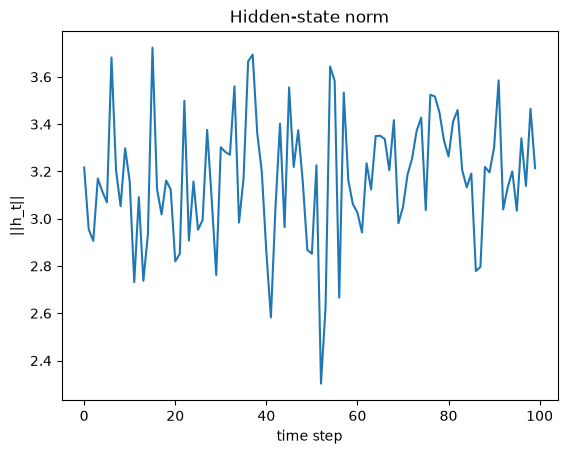

In [2]:
input_size, hidden_size, output_size = 50, 32, 2

torch.manual_seed(0)
W_xh = torch.randn(hidden_size, input_size) * 0.1
W_hh = torch.randn(hidden_size, hidden_size) * 0.1
b_h  = torch.randn(hidden_size) * 0.1
W_hy = torch.randn(output_size, hidden_size) * 0.1
b_y  = torch.randn(output_size) * 0.1

def rnn_forward(inputs):
    """inputs: list of tensors of shape (input_size,). Returns the list of hidden states and the final output."""
    h = torch.zeros(hidden_size)
    hiddens = []
    for x_t in inputs:
        h = torch.tanh(W_hh @ h + W_xh @ x_t + b_h)
        hiddens.append(h)
    y = W_hy @ h + b_y
    return hiddens, y

sequence = [torch.randn(input_size) for _ in range(100)]   # a stand-in for a 100-word review
hiddens, y = rnn_forward(sequence)

def check_rnn_forward(hiddens, y):
    """Compare your answer with PyTorch's nn.RNN loaded with the same weights."""
    ref = nn.RNN(input_size, hidden_size, batch_first=True)
    head = nn.Linear(hidden_size, output_size)
    with torch.no_grad():
        ref.weight_ih_l0.copy_(W_xh); ref.weight_hh_l0.copy_(W_hh)
        ref.bias_ih_l0.copy_(b_h);    ref.bias_hh_l0.zero_()
        head.weight.copy_(W_hy);      head.bias.copy_(b_y)
        ref_h, _ = ref(torch.stack(sequence).unsqueeze(0))
        ref_y = head(ref_h[0, -1])
    if len(hiddens) != len(sequence):
        print(f"✗ Expected {len(sequence)} hidden states, got {len(hiddens)}.")
    elif not all(torch.allclose(h, r, atol=1e-5) for h, r in zip(hiddens, ref_h[0])):
        print("✗ Hidden states don't match. Check the update: which two terms go inside tanh, and which weight goes with each?")
    elif not torch.allclose(y, ref_y, atol=1e-5):
        print("✓ Hidden states are correct.  ✗ Output doesn't match: which hidden state, which weight, which bias?")
    else:
        print("✓ Correct! Your RNN matches PyTorch's nn.RNN exactly.")

if not isinstance(y, torch.Tensor):
    print("Fill in the two TODO lines above, then re-run this cell. (The rest of the notebook runs without it.)")
else:
    check_rnn_forward(hiddens, y)
    # h_t is a vector (32 numbers), so we plot its length ||h_t|| -- one number per step
    plt.plot([h.norm().item() for h in hiddens])
    plt.xlabel('time step'); plt.ylabel('||h_t||'); plt.title('Hidden-state norm'); plt.show()


### ✏️ Quick check
1. How many learnable parameters does this RNN have?
2. Which variable carries information from one word to the next?
3. Can $\|\mathbf{h}_t\|$ grow without limit? Why not?


**Answers:**
1. There are $32(50) + 32(32) + 32 + 2(32) + 2 = 2722$ learnable parameters (including the output layer).
2. The hidden state `h` carries information from one word to the next.
3. No. Each component of `h` is bounded by `tanh` between -1 and 1, so its Euclidean norm is at most $\sqrt{32}$.


---
## Part 1: From Text to Tensors

**Dataset:** 50,000 IMDB reviews labelled positive or negative. We use 12,000 for training and 2,000 for testing.


In [3]:
def download_imdb(cache_dir='./data'):
    """Download the Stanford IMDB dataset once; return (train, test) lists of (label, text)."""
    os.makedirs(cache_dir, exist_ok=True)
    cached = os.path.join(cache_dir, 'imdb.pt')
    if os.path.exists(cached):
        return torch.load(cached)
    tar_path = os.path.join(cache_dir, 'aclImdb_v1.tar.gz')
    if not os.path.exists(tar_path):
        print("Downloading IMDB (~80 MB)...")
        urllib.request.urlretrieve('https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz', tar_path)
    data = {'train': [], 'test': []}
    with tarfile.open(tar_path, 'r:gz') as tar:
        for m in tar.getmembers():
            parts = m.name.split('/')            # aclImdb/train/pos/123_8.txt
            if len(parts) == 4 and parts[1] in data and parts[2] in ('pos', 'neg'):
                text = tar.extractfile(m).read().decode('utf-8')
                data[parts[1]].append((1 if parts[2] == 'pos' else 0, text))
    torch.save((data['train'], data['test']), cached)
    return data['train'], data['test']

all_train, all_test = download_imdb()
rng = np.random.default_rng(0)
train_raw = [all_train[i] for i in rng.permutation(len(all_train))[:12000]]
test_raw  = [all_test[i]  for i in rng.permutation(len(all_test))[:2000]]
CLASSES = ['Negative', 'Positive']
print(len(train_raw), "train reviews,", len(test_raw), "test reviews")


12000 train reviews, 2000 test reviews


### TODO: What are `train_raw` and `test_raw`?
What type is each element? Where is the label, and where is the text? Print one example.


In [4]:
# Each split is a list of (label, text) tuples.
# The label is an integer: 0 = Negative, 1 = Positive; the text is a string.
print("Split types:", type(train_raw).__name__, type(test_raw).__name__)
label, text = train_raw[0]
print("Element type:", type(train_raw[0]).__name__)
print("Label:", label, CLASSES[label], "| type:", type(label).__name__)
print("Text type:", type(text).__name__)
print("Example review:", text)


Split types: list list
Element type: tuple
Label: 1 Positive | type: int
Text type: str
Example review: We always watch American movies with their particular accents from each region (south, west, etc). We have the same here. All foreign people must to watch this movie and need to have a open mind to accept another culture, besides American and European almost dominate the cinematographic industry.<br /><br />This movie tell us about a parallel world which it isn't figured even for those who live in a big city like São Paulo. All actors are improvising and they are very realistic. The camera give us an idea of their confuse world, the loneliness of each character and invite us to share their world.<br /><br />It's a real great movie and worst a rent even have it at home.


### Counter — the GOAT data structure
A `Counter` counts things. It's how we'll build the vocabulary: count every word in the training reviews, keep the most common.


In [5]:
# Demo: count the words in a few strings, then print keys and values.
demo_reviews = ["good movie good acting", "bad movie good music"]
demo_counts = Counter(word for review in demo_reviews for word in review.split())
print("Counter:", demo_counts)
print("Keys:", list(demo_counts.keys()))
print("Values:", list(demo_counts.values()))


Counter: Counter({'good': 3, 'movie': 2, 'acting': 1, 'bad': 1, 'music': 1})
Keys: ['good', 'movie', 'acting', 'bad', 'music']
Values: [3, 2, 1, 1, 1]


### Tokenize, build a vocabulary, encode

- **Tokenize:** lowercase, strip HTML, split into words.
- **Vocabulary:** the 20,000 most common training words, each mapped to an integer. Two special entries: `<pad>` = 0 and `<unk>` = 1 (any word not in the vocabulary).
- **Encode:** keep the **last 200 words** of each review (reviewers usually put the verdict at the end), and **left-pad** shorter reviews with zeros so every review is exactly 200 numbers long. Because the padding is at the *front*, the last position is always the review's real last word. (59% of reviews fit entirely in 200 words.)

Why pad at all? A batch is one `(64, 200)` tensor, so every row must be the same length; reviews range from 10 to 2,500 words.


In [6]:
MAX_LEN = 200

def tokenize(text):
    text = re.sub(r'<[^>]+>', ' ', text.lower())      # IMDB reviews contain <br /> tags
    return re.findall(r"[a-z0-9']+|[!?]", text)

counts = Counter(word for _, text in train_raw for word in tokenize(text))
vocab = {'<pad>': 0, '<unk>': 1}
for word, _ in counts.most_common(20000 - 2):
    vocab[word] = len(vocab)

def encode(text):
    ids = [vocab.get(w, 1) for w in tokenize(text)][-MAX_LEN:]    # last MAX_LEN words
    return [0] * (MAX_LEN - len(ids)) + ids                       # left-pad with <pad> = 0

X_train = torch.tensor([encode(t) for _, t in train_raw])
y_train = torch.tensor([label for label, _ in train_raw])
X_test  = torch.tensor([encode(t) for _, t in test_raw])
y_test  = torch.tensor([label for label, _ in test_raw])
print("X_train:", X_train.shape, " y_train:", y_train.shape, " vocabulary:", len(vocab))


X_train: torch.Size([12000, 200])  y_train: torch.Size([12000])  vocabulary: 20000


### TODO: What is in `X_train`?
What do the numbers in one row mean? Why do many rows start with zeros? Decode the last 15 numbers of row 0 back into words.


In [7]:
# Each row contains vocabulary IDs for the last 200 tokens of one review.
# Leading zeros are <pad> tokens added when a review has fewer than 200 tokens.
# ID 1 is <unk>, used for tokens outside the training vocabulary.
id_to_word = {idx: word for word, idx in vocab.items()}
last_ids = X_train[0, -15:].tolist()
print("Last 15 token IDs:", last_ids)
print("Decoded words:", " ".join(id_to_word[idx] for idx in last_ids))
print("Padding tokens in row 0:", (X_train[0] == 0).sum().item())


Last 15 token IDs: [176, 42, 3, 145, 84, 16, 4, 241, 3, 858, 58, 25, 9, 31, 343]
Decoded words: world it's a real great movie and worst a rent even have it at home
Padding tokens in row 0: 82


### Pretrained word vectors (GloVe)
Instead of learning a vector for every word from scratch, we start from **GloVe** vectors trained on 6 billion words — "terrible" and "awful" already point in similar directions. If the download fails, the models start from random vectors and still work, just a little worse.


In [8]:
EMBED_DIM = 50

def load_glove(vocab, dim=EMBED_DIM, cache_dir='./data'):
    """Return a (len(vocab), dim) matrix: GloVe vectors for known words, small random vectors otherwise."""
    cached = os.path.join(cache_dir, f'glove{dim}_{len(vocab)}.pt')
    if os.path.exists(cached):
        return torch.load(cached)
    zip_path = os.path.join(cache_dir, 'glove.6B.zip')
    if not os.path.exists(zip_path):
        print("Downloading GloVe (~860 MB, one time)...")
        urllib.request.urlretrieve('https://nlp.stanford.edu/data/glove.6B.zip', zip_path)
    E = torch.randn(len(vocab), dim) * 0.1
    E[0] = 0                                                   # <pad> is the zero vector
    with zipfile.ZipFile(zip_path) as z, z.open(f'glove.6B.{dim}d.txt') as f:
        for line in f:
            word, *nums = line.decode('utf-8').split()
            if word in vocab:
                E[vocab[word]] = torch.tensor([float(n) for n in nums])
    torch.save(E, cached)
    return E

try:
    glove = load_glove(vocab)
    print("Loaded GloVe:", glove.shape)
except Exception as e:
    print("GloVe not available, using random embeddings:", e)
    glove = None


Loaded GloVe: torch.Size([20000, 50])


### The DataLoader
Same pattern as the Sonar baseline: wrap the tensors in a `TensorDataset`, hand it to a `DataLoader`.


In [9]:
BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE,
                          shuffle=True, generator=torch.Generator().manual_seed(0))


In [10]:
# 12,000 reviews / 64 per batch gives 188 batches; the last has 32 reviews.
print("Number of batches:", len(train_loader))
x_batch, y_batch = next(iter(train_loader))
print("x_batch:", x_batch.shape, "y_batch:", y_batch.shape)
print("Last batch size:", len(train_loader.dataset) % BATCH_SIZE or BATCH_SIZE)


Number of batches: 188
x_batch: torch.Size([64, 200]) y_batch: torch.Size([64])
Last batch size: 32


---
## Part 2: The Model

```
token ids (batch, 200) → Embedding → (batch, 200, 50) → RNN or LSTM → (batch, 200, 64) → last step → Linear → (batch, 2)
```

`nn.RNN` and `nn.LSTM` take the same arguments and return the same `out` tensor, so one class covers both. The LSTM is here so you can compare results; we'll look inside it in a later lesson.


In [11]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=EMBED_DIM, hidden_size=64, cell='RNN', embeddings=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        if embeddings is not None:
            self.embedding.weight.data.copy_(embeddings)
        RNNLayer = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[cell]
        self.rnn = RNNLayer(embed_dim, hidden_size, num_layers=2, batch_first=True)
        self.fc = nn.Linear(hidden_size, 2)

    def forward(self, x):
        out, _ = self.rnn(self.embedding(x))     # out: (batch, seq_len, hidden_size)
        return self.fc(out[:, -1])               # hidden state after the last word -> 2 scores


def make_experiment(cell):
    """Build the model, the loss, and the optimizer (same shape as the Sonar baseline)."""
    model = SentimentRNN(len(vocab), cell=cell, embeddings=glove).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    return model, loss_fn, optimizer


### ✏️ Shapes
For one batch: what is the shape after `self.embedding(x)`? After `self.rnn(...)`? What does `out[:, -1]` select, and why is that the right step only because we left-padded?


**Answers (batch size 64):**
- `self.embedding(x)` has shape `(64, 200, 50)`: 64 reviews, 200 tokens per review, and 50 features per token.
- `self.rnn(...)` returns a tuple. Its `out` tensor has shape `(64, 200, 64)` for both RNN and LSTM: the top recurrent layer's 64-dimensional hidden state at every position. With two layers, the final hidden state has shape `(2, 64, 64)`; the LSTM also returns a cell state of this shape.
- `out[:, -1]` selects the last time step for every review, giving shape `(64, 64)`. Left padding puts the padding before the real words, so the last position is the last real token for every nonempty review. With right padding, shorter reviews would end on padding instead.
- The final linear layer produces `(64, 2)` logits, one score for each class. `CrossEntropyLoss` takes these logits directly, without a separate softmax.


In [12]:
# Inspect one batch through each model, without training.
# Preserve the random state so this demonstration does not affect later experiments.
with torch.random.fork_rng(devices=[]), torch.no_grad():
    for cell_type in ('RNN', 'LSTM'):
        demo_model, demo_loss_fn, demo_optimizer = make_experiment(cell_type)
        demo_model.eval()
        demo_x = x_batch.to(device)
        demo_emb = demo_model.embedding(demo_x)
        demo_out, demo_state = demo_model.rnn(demo_emb)
        demo_logits = demo_model(demo_x)
        print(f"{cell_type}: input {tuple(demo_x.shape)} -> embedding {tuple(demo_emb.shape)}"
              f" -> recurrent output {tuple(demo_out.shape)} -> last step {tuple(demo_out[:, -1].shape)}"
              f" -> logits {tuple(demo_logits.shape)}")
        if cell_type == 'LSTM':
            print("  h_n:", tuple(demo_state[0].shape), "c_n:", tuple(demo_state[1].shape))
        else:
            print("  h_n:", tuple(demo_state.shape))
        print("  Loss:", type(demo_loss_fn).__name__, "Optimizer:", type(demo_optimizer).__name__)


RNN: input (64, 200) -> embedding (64, 200, 50) -> recurrent output (64, 200, 64) -> last step (64, 64) -> logits (64, 2)
  h_n: (2, 64, 64)
  Loss: CrossEntropyLoss Optimizer: Adam
LSTM: input (64, 200) -> embedding (64, 200, 50) -> recurrent output (64, 200, 64) -> last step (64, 64) -> logits (64, 2)
  h_n: (2, 64, 64) c_n: (2, 64, 64)
  Loss: CrossEntropyLoss Optimizer: Adam


---
## Part 3: Training

Same loop as the Sonar baseline. One addition: `clip_grad_norm_` returns the **total gradient norm** for the step, which we record. It only clips if you pass a `clip` value.


In [13]:
@torch.no_grad()
def predict_proba(model, X, batch_size=500):
    """P(positive) for every row of X."""
    model.eval()
    return torch.cat([torch.softmax(model(X[i:i + batch_size].to(device)), dim=1)[:, 1].cpu()
                      for i in range(0, len(X), batch_size)])

def accuracy(model, X, y):
    return ((predict_proba(model, X) > 0.5).long() == y).float().mean().item()


def train(model, loss_fn, optimizer, loader, n_epochs=10, clip=None, verbose=True):
    """Train the model. Returns per-epoch training loss and per-step gradient norm."""
    losses, grad_norms = [], []
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0.0
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            # Forward pass
            loss = loss_fn(model(x_batch), y_batch)

            # Backward pass and update
            optimizer.zero_grad()
            loss.backward()
            norm = nn.utils.clip_grad_norm_(model.parameters(), clip if clip else float('inf'))
            grad_norms.append(norm.item())
            optimizer.step()

            epoch_loss += loss.item() * len(y_batch)

        losses.append(epoch_loss / len(loader.dataset))
        if verbose:
            print(f"Epoch {epoch + 1:2d}  loss {losses[-1]:.4f}  test acc {accuracy(model, X_test, y_test):.3f}")
    return losses, grad_norms


Build both models now — **before training** — so we can measure their gradients untrained in Part 4.


In [14]:
torch.manual_seed(0)
rnn,  rnn_loss_fn,  rnn_opt  = make_experiment('RNN')
lstm, lstm_loss_fn, lstm_opt = make_experiment('LSTM')
print("RNN parameters: ", sum(p.numel() for p in rnn.parameters()))
print("LSTM parameters:", sum(p.numel() for p in lstm.parameters()))


RNN parameters:  1015874
LSTM parameters: 1063106


---
## Part 4: How Much Gradient Reaches Each Word?

The lecture claimed the gradient from the prediction back to an early word shrinks exponentially with distance. We can measure it directly:

$$\left\| \frac{\partial \mathcal{L}}{\partial \mathbf{x}_t} \right\| \quad \text{for every word position } t$$

— "how much does the loss care about word $t$?" We compute it on test reviews that are at least 200 words long (no padding), so every position is a real word.


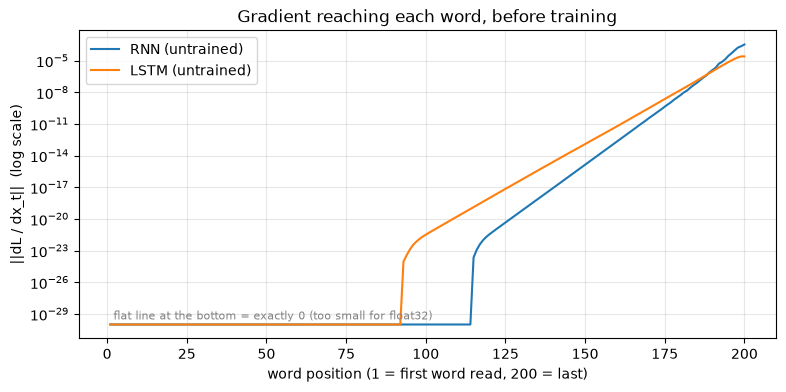

In [15]:
def gradient_by_position(model, X, y):
    """||d loss / d x_t|| at each word position, averaged over the reviews in X."""
    model.train()   # (no dropout here, so same as eval; CUDA's LSTM backward requires train mode)
    emb = model.embedding(X.to(device)).detach().requires_grad_()   # word vectors, tracked by autograd
    out, _ = model.rnn(emb)
    loss = loss_fn_ce(model.fc(out[:, -1]), y.to(device))
    loss.backward()
    return emb.grad.norm(dim=2).mean(dim=0).cpu().numpy()         # one number per position

def plot_gradients(profiles, title):
    plt.figure(figsize=(9, 4))
    for label, g in profiles.items():
        plt.semilogy(range(1, len(g) + 1), np.maximum(g, 1e-30), label=label)
    if any((g == 0).any() for g in profiles.values()):
        plt.text(2, 3e-30, 'flat line at the bottom = exactly 0 (too small for float32)', fontsize=8, color='gray')
    plt.xlabel('word position (1 = first word read, 200 = last)')
    plt.ylabel('||dL / dx_t||  (log scale)')
    plt.title(title); plt.grid(True, alpha=0.3); plt.legend(); plt.show()

loss_fn_ce = nn.CrossEntropyLoss()
full = X_test[:, 0] != 0                       # reviews with no padding
X_grad, y_grad = X_test[full][:256], y_test[full][:256]

untrained_profiles = {'RNN (untrained)': gradient_by_position(rnn, X_grad, y_grad),
                      'LSTM (untrained)': gradient_by_position(lstm, X_grad, y_grad)}
plot_gradients(untrained_profiles, 'Gradient reaching each word, before training')


### ✏️ Read the plot
1. The y-axis is logarithmic. Roughly how many orders of magnitude separate word 200 from word 1 for the RNN?
2. Why is it close to a straight line? (Day 1: a product of one factor per step.)
3. Predict: after training, will the RNN's line be flatter?


**Prediction before training (Q3):** Training may make the RNN's line somewhat flatter by changing the recurrent weights, but I expect gradients at early positions to remain much smaller than those near the last word. Training does not remove the repeated multiplication through time.


**Measured answers:**
1. The last-word gradient norm is about $3.43 \times 10^{-4}$, while word 1 is plotted at the $10^{-30}$ display floor: about **26.5 orders of magnitude on this plot**. The computed norm is actually zero for positions 1-114, so the true endpoint ratio cannot be calculated from these float32 results. The floor is for plotting, not a measured nonzero gradient.
2. Backpropagation through time multiplies a sequence of Jacobians, including the recurrent weights and the derivatives of `tanh`. When the typical factor contracts the gradient, its magnitude decays approximately exponentially with distance from the final prediction. Taking the logarithm turns that approximate exponential decay into a roughly straight line, until numerical underflow affects the computed norm.


### Train both models
10 epochs each. This is the slow part — several minutes per model. Start it and read ahead.


=== RNN ===


Epoch  1  loss 0.6541  test acc 0.660


Epoch  2  loss 0.5386  test acc 0.721


Epoch  3  loss 0.6087  test acc 0.661


Epoch  4  loss 0.5684  test acc 0.744


Epoch  5  loss 0.5139  test acc 0.706


... (11 outputs left out)

Epoch  7  loss 0.1524  test acc 0.836


Epoch  8  loss 0.1150  test acc 0.840


Epoch  9  loss 0.0825  test acc 0.832


Epoch 10  loss 0.0556  test acc 0.841


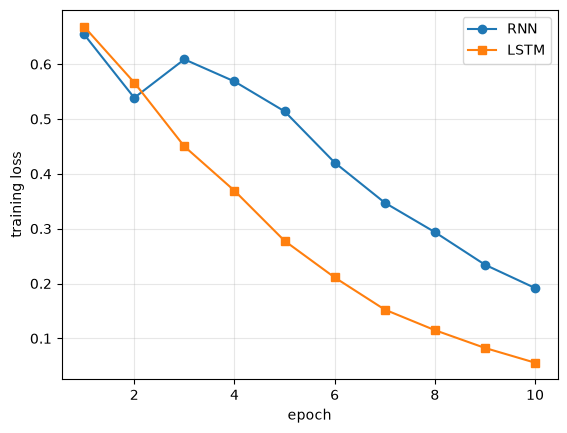

Test accuracy  RNN: 0.739   LSTM: 0.841


In [16]:
print("=== RNN ===")
rnn_losses, rnn_norms = train(rnn, rnn_loss_fn, rnn_opt, train_loader)
print("\n=== LSTM ===")
lstm_losses, lstm_norms = train(lstm, lstm_loss_fn, lstm_opt, train_loader)

plt.plot(range(1, 11), rnn_losses, 'o-', label='RNN')
plt.plot(range(1, 11), lstm_losses, 's-', label='LSTM')
plt.xlabel('epoch'); plt.ylabel('training loss'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()
print(f"Test accuracy  RNN: {accuracy(rnn, X_test, y_test):.3f}   LSTM: {accuracy(lstm, X_test, y_test):.3f}")


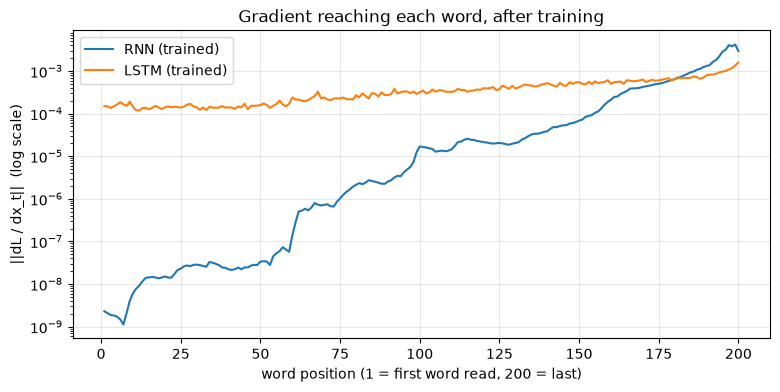

In [17]:
trained_profiles = {'RNN (trained)': gradient_by_position(rnn, X_grad, y_grad),
                    'LSTM (trained)': gradient_by_position(lstm, X_grad, y_grad)}
plot_gradients(trained_profiles, 'Gradient reaching each word, after training')


### ✏️ Reflect
1. Did training flatten the RNN's line? Roughly how many of the last words does the RNN actually use?
2. The RNN still scores well above 50%. How, if it only uses the last few words? (Which words did we keep?)
3. What does the LSTM's line let it do that the RNN can't?


**Answers from this run (256 test reviews with no padding):**
1. Yes, training made the RNN's curve much flatter, but a strong bias toward recent words remains. The gradient norm rises from about $2.30 \times 10^{-9}$ at word 1 to $2.94 \times 10^{-3}$ at word 200, a gap of about **6.1 orders of magnitude**. The strongest gradients are concentrated in roughly the **last 30 words**; using 1% of the peak as a looser threshold gives roughly the **last 60 words**. These are approximate sensitivity ranges, not a strict cutoff proving earlier words are unused.
2. The RNN reached **73.90%** test accuracy. We kept the **last 200 words** of each review, which often include the reviewer's conclusion and explicit sentiment words. Those ending cues can be enough to classify many reviews even when earlier context has little influence.
3. The LSTM's trained gradient stays much more uniform across the whole review: about $1.50 \times 10^{-4}$ at word 1 and $1.59 \times 10^{-3}$ at word 200, only about one order of magnitude apart. This gives learning a stronger signal from earlier words and makes longer-range context easier to retain. The LSTM reached **84.15%** test accuracy in this run, **10.25 percentage points** above the RNN.

Both models ran for the supplied 10 epochs. Final training losses were **0.1918** (RNN) and **0.0556** (LSTM). These results describe this run; they do not imply that every initialization will give the same curves or accuracy.


### Exploding gradients: the same plot, the other way
Scale $\mathbf{W}_{hh}$ up by 3. Day 1 predicts the per-step factor becomes $> 1$.


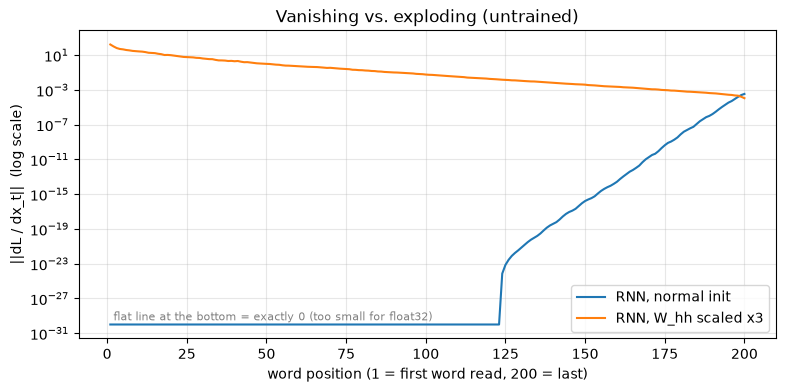

In [18]:
torch.manual_seed(0)
big_rnn, _, _ = make_experiment('RNN')
with torch.no_grad():
    big_rnn.rnn.weight_hh_l0 *= 3
    big_rnn.rnn.weight_hh_l1 *= 3

scaled_profiles = {'RNN, normal init': gradient_by_position(make_experiment('RNN')[0], X_grad, y_grad),
                   'RNN, W_hh scaled x3': gradient_by_position(big_rnn, X_grad, y_grad)}
plot_gradients(scaled_profiles, 'Vanishing vs. exploding (untrained)')


### ✏️ Clipping
`train(..., clip=1.0)` rescales the gradient whenever its norm exceeds 1. Which of the two lines above would clipping help? Which can it never help, and why?


**Answer:** Clipping would help control updates for the **orange curve, `RNN, W_hh scaled x3`**, which shows exploding gradients toward early positions. Its gradient norm is about **169** at word 1 and $1.12 \times 10^{-4}$ at word 200, an amplification of roughly **1.5 million times** when moving backward through the sequence.

Clipping cannot fix the vanishing gradients in the **blue, normal-initialization curve**. `clip_grad_norm_` rescales the model's total parameter-gradient norm when it exceeds the threshold; it does not amplify tiny gradients or recover a signal that has become numerically zero. It controls the size of the update, rather than directly clipping each input-gradient value shown in this plot or removing the repeated Jacobian products. The supplied training run used `clip=None`; this section explains what clipping would do, without claiming to have run the optional clipped-training experiment.


---
## Part 5: What Did the Models Learn?

### Try your own review
`score` gives P(positive). `plot_running_score` shows the prediction after **each word** — the hidden state's running opinion.


{'RNN': 0.2687349021434784, 'LSTM': 0.011325698345899582}


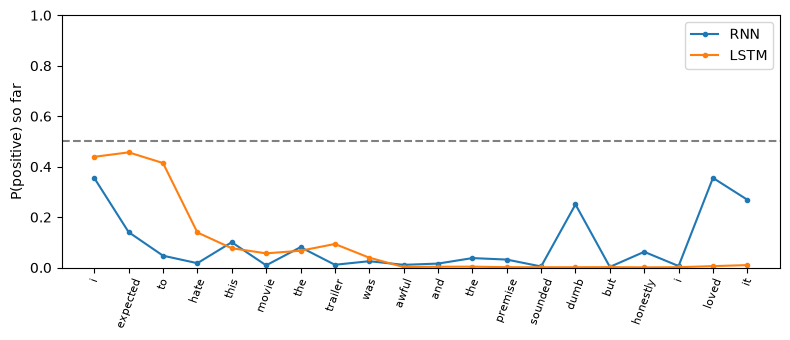

In [19]:
def score(text):
    x = torch.tensor([encode(text)])
    return {name: predict_proba(m, x).item() for name, m in [('RNN', rnn), ('LSTM', lstm)]}

@torch.no_grad()
def plot_running_score(text):
    words = tokenize(text)[-MAX_LEN:]
    x = torch.tensor([[vocab.get(w, 1) for w in words]]).to(device)
    plt.figure(figsize=(max(8, 0.3 * len(words)), 3.5))
    for name, m in [('RNN', rnn), ('LSTM', lstm)]:
        m.eval()
        out, _ = m.rnn(m.embedding(x))
        plt.plot(torch.softmax(m.fc(out[0]), dim=1)[:, 1].cpu(), 'o-', markersize=3, label=name)
    plt.axhline(0.5, color='gray', linestyle='--')
    plt.xticks(range(len(words)), words, rotation=70, fontsize=8)
    plt.ylim(0, 1); plt.ylabel('P(positive) so far'); plt.legend(); plt.tight_layout(); plt.show()

my_review = "I expected to hate this movie. The trailer was awful and the premise sounded dumb. But honestly, I loved it."
print(score(my_review))
plot_running_score(my_review)


### ✏️ Try it
1. Did either model get the review above right? Watch both lines: which one jumps with every word?
2. Write a review the LSTM gets right and the RNN gets wrong. Write one that fools both.


**Answers from the saved Part 4 models:**
1. Neither model gets the provided positive review right: `P(positive)` is **0.2687 for RNN** and **0.0113 for LSTM**, both below 0.5. The RNN's running opinion jumps more, while the LSTM is smoother but remains too negative after the initial negative phrases. A smoother curve does not guarantee a correct prediction. The running plot processes the unpadded text, while `score` uses the left-padded 200-token representation, so their final values can differ slightly.
2. The following two original examples were selected after testing candidate reviews. They demonstrate failure cases rather than measuring general accuracy:
   - **Positive; LSTM correct, RNN wrong:** "I loved this movie. It was beautifully acted, thoughtful, and deeply moving. The story explores grief, cruelty, and terrible suffering." The negative subject matter at the end is not a negative evaluation of the film.
   - **Negative; both wrong:** "Amazing! The best thing about this movie was how happy I felt when it finally ended." This is sarcastic relief that the film is over, despite positive surface words.


Expected: Positive
I loved this movie. It was beautifully acted, thoughtful, and deeply moving. The story explores grief, cruelty, and terrible suffering.
  RNN: P(positive)=0.0944, predicted=Negative
  LSTM: P(positive)=0.9989, predicted=Positive


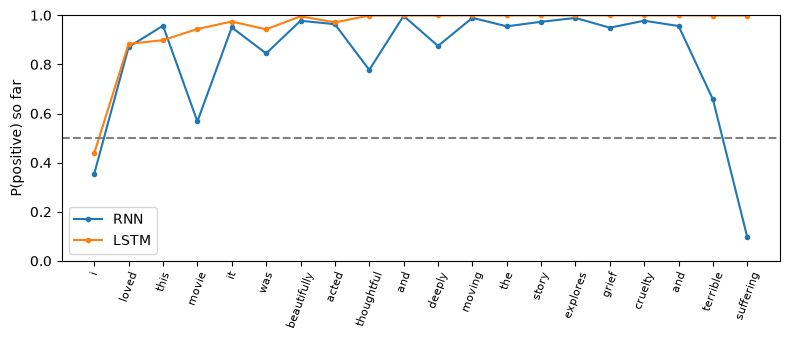

Expected: Negative
Amazing! The best thing about this movie was how happy I felt when it finally ended.
  RNN: P(positive)=0.9953, predicted=Positive
  LSTM: P(positive)=0.9906, predicted=Positive


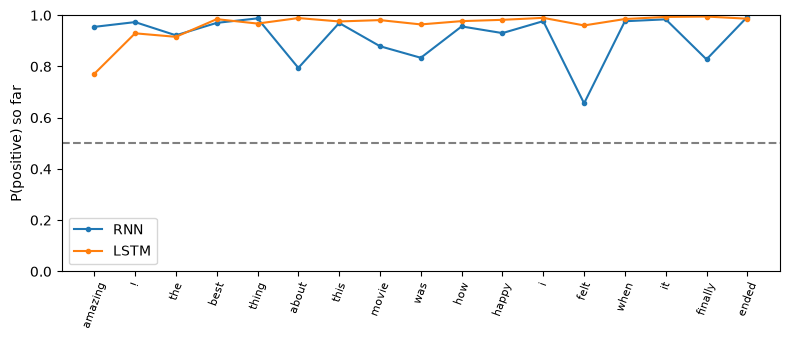

In [20]:
custom_reviews = [
    (1, "I loved this movie. It was beautifully acted, thoughtful, and deeply moving. The story explores grief, cruelty, and terrible suffering."),
    (0, "Amazing! The best thing about this movie was how happy I felt when it finally ended."),
]
custom_results = []
for expected_label, review in custom_reviews:
    probabilities = score(review)
    custom_results.append({'label': expected_label, 'text': review, 'probabilities': probabilities})
    print("Expected:", CLASSES[expected_label])
    print(review)
    for name, probability in probabilities.items():
        print(f"  {name}: P(positive)={probability:.4f}, predicted={CLASSES[int(probability > 0.5)]}")
    plot_running_score(review)


### Five right, five wrong
For each model: the 5 test reviews it got right with the most confidence, and the 5 it got wrong with the most confidence (last 40 words shown).


In [21]:
def show_examples(model, name, n=5):
    p = predict_proba(model, X_test).numpy()
    y = y_test.numpy()
    right = np.where((p > 0.5) == y)[0]
    wrong = np.where((p > 0.5) != y)[0]
    confidence = np.abs(p - 0.5)
    for title, idx in [('RIGHT', right), ('WRONG', wrong)]:
        print(f"\n=== {name}: {n} most confident {title} ===")
        for i in idx[np.argsort(-confidence[idx])][:n]:
            print(f"[true {CLASSES[y[i]]}, P(positive) = {p[i]:.2f}]  ...{' '.join(tokenize(test_raw[i][1])[-40:])}\n")

show_examples(rnn, 'RNN')
show_examples(lstm, 'LSTM')



=== RNN: 5 most confident RIGHT ===
[true Negative, P(positive) = 0.00]  ...before me felt the same way because they didn't rewind the tape and left off about the same place i did the only reason i gave this a score of 1 is because the rating system doesn't have negative numbers

[true Positive, P(positive) = 1.00]  ...pfeiffer ? i was wrong they are wonderful together they reminded me this time to the barbara stanwyck fred macmurray of remember the night i'm writing this comment now to entice you to visit or revisit this jonathan demme gem

[true Positive, P(positive) = 1.00]  ...often i find it amazing that these people can ad lib so much funny material for each movie ! what a fun bunch they must be i highly recommend this to people who prefer their humor on the cerebral side

[true Positive, P(positive) = 1.00]  ...who has selflessly dedicated her life to helping those in need and to filmmakers like robbins and sarandon for bringing her to life for millions of people who otherwise 

### ✏️ Look at the mistakes
1. What do the confident mistakes have in common?
2. For the RNN's mistakes, does the *ending* of the review sound like the label the RNN predicted? What does that tell you?


**Answers based on the displayed cases and their full review text:**
1. Several mistakes mix praise and criticism, use negation or sarcasm, or discuss the plot/DVD separately from the quality of the film. Confidence is not reliability. Some LSTM errors also suggest ambiguous or inconsistent dataset labels: one review ends with **8/10** and strong praise but is labelled negative. This is evidence of possible label noise, not proof that all confident errors are labelling mistakes; the supplied labels are kept unchanged.
2. Some RNN mistakes fit the ending-bias explanation. A negative review ends by praising Hawaiian shirts, and the RNN predicts positive. A positive review ends with complaints about a faulty DVD transfer and corrupted short film, and the RNN predicts negative. However, other negative reviews have clearly negative endings and are still predicted positive. Recency bias explains some failures, while negation, word associations, and generalization errors also matter.


---
## Part 6: Reflection

Answer in a few sentences each.

**Q1.** Describe the untrained RNN's gradient-by-position plot and explain its shape with the chain rule through time.

**Q2.** The RNN only uses the last few words, yet scores well above chance. Explain, and describe a review it would get wrong.

**Q3.** Gradient clipping fixes one of the two problems in Part 4 and not the other. Which, and why?

**Q4.** In Lab 4, ReLU fixed vanishing gradients in MLPs. Why can't we just use ReLU in an RNN?


**Q1.** Before training, the RNN's gradient becomes much smaller as we move backward from word 200 toward word 1. The positive part is approximately a straight line on the logarithmic plot because the chain rule multiplies many recurrent Jacobians; repeated contraction produces roughly exponential decay. In this float32 computation, the early-position norms become zero and are displayed at the plotting floor, so the flat bottom is a numerical limit rather than evidence of a true nonzero gradient.

**Q2.** We retain the last 200 tokens, which often contain a reviewer's final verdict and strong sentiment words, so a model biased toward recent words can still exceed chance. Our trained RNN achieved 73.90%, with the strongest gradients concentrated near the end rather than a strict cutoff that makes all earlier words irrelevant. For example, it predicts negative for the positive review that praises the film but ends with "grief, cruelty, and terrible suffering": the ending describes the story's subject, not the reviewer's opinion.

**Q3.** Gradient clipping limits exploding parameter gradients and thereby helps prevent excessively large updates. It cannot repair vanishing gradients: scaling a large total norm down does not strengthen tiny earlier gradients or recover a signal lost to numerical underflow. It controls an update's magnitude, not the recurrent chain of multiplications itself.

**Q4.** We can implement a ReLU RNN, but replacing `tanh` with ReLU is not a general solution. Active ReLU units have derivative 1, yet backpropagation still repeatedly multiplies by the recurrent weight matrix; those products can contract or explode. Inactive units have derivative 0, and ReLU's unbounded activations can also grow across time. LSTM and GRU add gated state paths that help control what is retained, rather than merely swapping the activation function.


---
## Extensions (optional)
- **Wrong end of the review:** change `encode` to keep the *first* 200 words. Retrain the RNN. What happens, and why?
- **Clipping in action:** train `big_rnn` with `torch.optim.SGD(big_rnn.parameters(), lr=0.3)` for 2 epochs, with and without `clip=1.0`. Plot the returned gradient norms and compare `big_rnn.rnn.weight_hh_l0.abs().max()` afterward.
- **GRU:** add `nn.GRU` as a third option in `SentimentRNN` and compare.


### Extension setup

The experiments below leave the original `rnn`, `lstm`, tokenization, and test labels intact. The first-token experiment keeps the training vocabulary, model initialization, optimizer, batch size, and epoch count fixed; only which end of each review is retained changes. The clipping pair starts from identical scaled recurrent weights and uses identical minibatch order. Any nonfinite training result is reported as numerical divergence rather than hidden or replaced.


In [22]:
import copy

def extension_loader(X, y, match_baseline=False):
    loader = DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(0))
    if match_baseline:
        # Part 1 inspected one batch before the original training run.
        next(iter(loader))
    return loader

def train_extension(model, optimizer, loader, X_eval, y_eval, epochs, clip=None):
    history = {'losses': [], 'accuracies': [], 'gradient_norms': [], 'status': 'completed'}
    criterion = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        total_loss, seen = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss):
                history['status'] = f'nonfinite loss during epoch {epoch + 1}'
                print(history['status'])
                return history
            loss.backward()
            norm = nn.utils.clip_grad_norm_(model.parameters(), clip if clip is not None else float('inf'))
            history['gradient_norms'].append(float(norm))
            if not torch.isfinite(norm):
                history['status'] = f'nonfinite gradient norm during epoch {epoch + 1}; update skipped'
                print(history['status'])
                return history
            optimizer.step()
            total_loss += loss.item() * len(yb)
            seen += len(yb)
        history['losses'].append(total_loss / seen)
        history['accuracies'].append(accuracy(model, X_eval, y_eval))
        print(f"Epoch {epoch + 1:2d}: loss={history['losses'][-1]:.4f}, test accuracy={history['accuracies'][-1]:.4f}")
    return history


### Extension 1 — Keep the first 200 tokens

Both architectures are retrained for 10 epochs on the first-token representation. Short reviews are still left-padded; the vocabulary is unchanged. Both models are initialized together using the same seed and creation order as the original pair.


=== FIRST 200: RNN ===


Epoch  1: loss=0.6756, test accuracy=0.4885


Epoch  2: loss=0.6890, test accuracy=0.5725


Epoch  3: loss=0.6546, test accuracy=0.6600


Epoch  4: loss=0.5702, test accuracy=0.6125


Epoch  5: loss=0.5554, test accuracy=0.7345


... (11 outputs left out)

Epoch  7: loss=0.2148, test accuracy=0.8210


Epoch  8: loss=0.1586, test accuracy=0.7940


Epoch  9: loss=0.1196, test accuracy=0.8225


Epoch 10: loss=0.0857, test accuracy=0.8210
RNN: last 200 = 0.7390; first 200 = 0.7320
LSTM: last 200 = 0.8415; first 200 = 0.8210


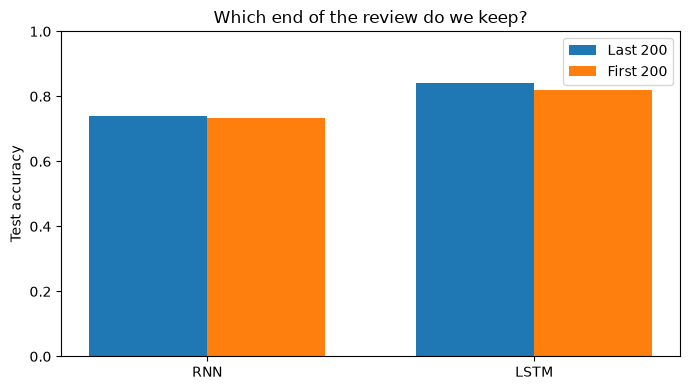

In [23]:
def encode_first(text):
    ids = [vocab.get(w, 1) for w in tokenize(text)][:MAX_LEN]
    return [0] * (MAX_LEN - len(ids)) + ids

X_train_first = torch.tensor([encode_first(text) for _, text in train_raw])
X_test_first = torch.tensor([encode_first(text) for _, text in test_raw])
first_loader = extension_loader(X_train_first, y_train, match_baseline=True)
torch.manual_seed(0)
first_rnn, _, first_rnn_opt = make_experiment('RNN')
first_lstm, _, first_lstm_opt = make_experiment('LSTM')
print('=== FIRST 200: RNN ===')
first_rnn_history = train_extension(first_rnn, first_rnn_opt, first_loader, X_test_first, y_test, epochs=10)
print('=== FIRST 200: LSTM ===')
first_lstm_history = train_extension(first_lstm, first_lstm_opt, first_loader, X_test_first, y_test, epochs=10)
first_results = {
    'RNN': {'last_200_accuracy': accuracy(rnn, X_test, y_test), 'first_200_accuracy': accuracy(first_rnn, X_test_first, y_test)},
    'LSTM': {'last_200_accuracy': accuracy(lstm, X_test, y_test), 'first_200_accuracy': accuracy(first_lstm, X_test_first, y_test)},
}
for name, result in first_results.items():
    print(f"{name}: last 200 = {result['last_200_accuracy']:.4f}; first 200 = {result['first_200_accuracy']:.4f}")
plt.figure(figsize=(7, 4))
positions = np.arange(2)
plt.bar(positions - .18, [first_results[n]['last_200_accuracy'] for n in ['RNN', 'LSTM']], width=.36, label='Last 200')
plt.bar(positions + .18, [first_results[n]['first_200_accuracy'] for n in ['RNN', 'LSTM']], width=.36, label='First 200')
plt.xticks(positions, ['RNN', 'LSTM']); plt.ylim(0, 1); plt.ylabel('Test accuracy')
plt.title('Which end of the review do we keep?'); plt.legend(); plt.tight_layout(); plt.show()


**Observed result:** With the first 200 tokens, RNN accuracy is **73.20%**, compared with **73.90%** for the last 200 (a drop of **0.70 percentage points**). LSTM accuracy is **82.10%**, compared with **84.15%** (a drop of **2.05 percentage points**).

Keeping the ending helps in this run, but neither model collapses when given the beginning. Many reviews contain sentiment in the opening too, and reviews of at most 200 tokens are unchanged by this experiment. The result supports the usefulness of ending cues without proving that endings always contain more information. These are single-seed runs, so small differences should not be treated as statistically established rankings.


### Extension 2 — SGD with and without gradient clipping

Both copies start from the same untrained RNN with both recurrent weight matrices multiplied by 3. We train each for two epochs with SGD at learning rate 0.3. The recorded norms are measured **before clipping**, since that is what `clip_grad_norm_` returns.


=== No clipping ===


C:\Dev\COMP395\deeplearning_env\Lib\site-packages\torch\nn\modules\rnn.py:728: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1480.)
  result = _VF.rnn_tanh(


Epoch  1: loss=1.5582, test accuracy=0.5045


Epoch  2: loss=1.8005, test accuracy=0.5185
{'status': 'completed', 'completed_epochs': 2, 'initial_weight_hh_l0_max': 0.3749561309814453, 'final_weight_hh_l0_max': 780.5350952148438, 'peak_preclip_gradient_norm': 85686.5078125, 'test_accuracy': 0.5184999704360962}
=== clip=1.0 ===


Epoch  1: loss=0.7805, test accuracy=0.5145


Epoch  2: loss=0.7885, test accuracy=0.5135
{'status': 'completed', 'completed_epochs': 2, 'initial_weight_hh_l0_max': 0.3749561309814453, 'final_weight_hh_l0_max': 0.4658263623714447, 'peak_preclip_gradient_norm': 419282.40625, 'test_accuracy': 0.5134999752044678}


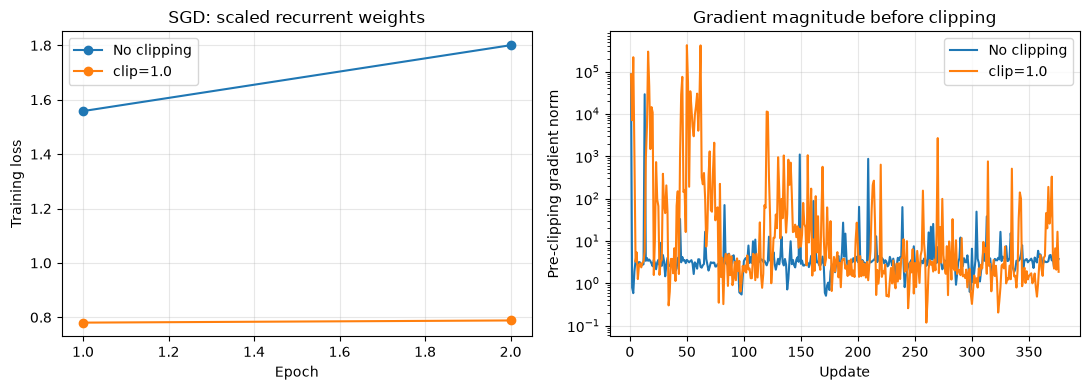

In [24]:
torch.manual_seed(0)
clip_template, _, _ = make_experiment('RNN')
with torch.no_grad():
    clip_template.rnn.weight_hh_l0 *= 3
    clip_template.rnn.weight_hh_l1 *= 3
clip_models, clip_histories, clip_results = {}, {}, {}
initial_hh_max = float(clip_template.rnn.weight_hh_l0.detach().abs().max())
for label, threshold in [('No clipping', None), ('clip=1.0', 1.0)]:
    model = copy.deepcopy(clip_template)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.3)
    print('===', label, '===')
    history = train_extension(model, optimizer, extension_loader(X_train, y_train), X_test, y_test, epochs=2, clip=threshold)
    clip_models[label], clip_histories[label] = model, history
    clip_results[label] = {
        'status': history['status'], 'completed_epochs': len(history['losses']),
        'initial_weight_hh_l0_max': initial_hh_max,
        'final_weight_hh_l0_max': float(model.rnn.weight_hh_l0.detach().abs().max()),
        'peak_preclip_gradient_norm': max(history['gradient_norms'], default=0.0),
        'test_accuracy': accuracy(model, X_test, y_test),
    }
    print(clip_results[label])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, history in clip_histories.items():
    axes[0].plot(range(1, len(history['losses']) + 1), history['losses'], 'o-', label=label)
    axes[1].semilogy(range(1, len(history['gradient_norms']) + 1), np.maximum(history['gradient_norms'], 1e-30), label=label)
axes[0].set(xlabel='Epoch', ylabel='Training loss', title='SGD: scaled recurrent weights')
axes[1].set(xlabel='Update', ylabel='Pre-clipping gradient norm', title='Gradient magnitude before clipping')
for ax in axes:
    ax.grid(True, alpha=.3); ax.legend()
plt.tight_layout(); plt.show()


**Observed result after two SGD epochs:**

| Setting | Initial max abs value of `weight_hh_l0` | Final max abs value | Final training loss | Test accuracy |
|---|---:|---:|---:|---:|
| No clipping | 0.37496 | 780.53510 | 1.8005 | 51.85% |
| `clip=1.0` | 0.37496 | 0.46583 | 0.7885 | 51.35% |

Clipping strongly limits the growth of the recurrent weights and gives a much lower loss in this deliberately unstable setup. It does **not** yield useful classification within these two epochs: both accuracies remain close to chance. Preventing a huge update is not the same as solving the learning problem.

The orange norm curve can still exceed 1 because the plot records the norm **before** rescaling. Its peak is about 419,282; the unclipped run peaks near 85,687. After their first different updates the models follow different parameter trajectories, so comparing their pre-clipping peaks alone does not measure clipping's effectiveness. For finite gradients the clipped update uses a total gradient norm of at most approximately 1.


### Extension 3 — GRU

The model factory now also accepts `cell='GRU'`. This experiment uses the original last-200-token data, two recurrent layers, hidden size 64, GloVe initialization, Adam at 0.001, and 10 epochs. It compares accuracy and the trained gradient-by-position profile with the original RNN and LSTM.


GRU parameters: 1047362


Epoch  1: loss=0.5937, test accuracy=0.7695


Epoch  2: loss=0.3663, test accuracy=0.8515


Epoch  3: loss=0.2510, test accuracy=0.8555


Epoch  4: loss=0.1684, test accuracy=0.8535


Epoch  5: loss=0.1011, test accuracy=0.8545


Epoch  6: loss=0.0538, test accuracy=0.8550


Epoch  7: loss=0.0242, test accuracy=0.8525


Epoch  8: loss=0.0086, test accuracy=0.8475


Epoch  9: loss=0.0044, test accuracy=0.8475


Epoch 10: loss=0.0019, test accuracy=0.8485


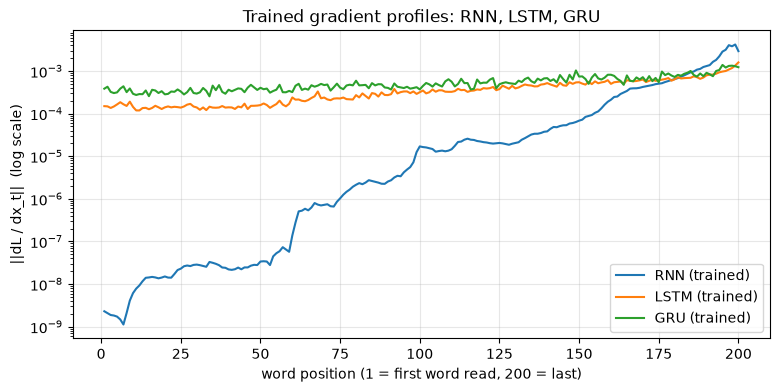

RNN {'test_accuracy': 0.7390000224113464, 'parameters': 1015874}
LSTM {'test_accuracy': 0.8414999842643738, 'parameters': 1063106}
GRU {'test_accuracy': 0.8485000133514404, 'parameters': 1047362}


In [25]:
torch.manual_seed(0)
gru, _, gru_optimizer = make_experiment('GRU')
print('GRU parameters:', sum(p.numel() for p in gru.parameters()))
gru_history = train_extension(gru, gru_optimizer, extension_loader(X_train, y_train, match_baseline=True), X_test, y_test, epochs=10)
gru_profile = gradient_by_position(gru, X_grad, y_grad)
plot_gradients({**trained_profiles, 'GRU (trained)': gru_profile}, 'Trained gradient profiles: RNN, LSTM, GRU')
model_comparison = {}
for name, model in [('RNN', rnn), ('LSTM', lstm), ('GRU', gru)]:
    model_comparison[name] = {'test_accuracy': accuracy(model, X_test, y_test), 'parameters': sum(p.numel() for p in model.parameters())}
    print(name, model_comparison[name])


**Observed result:** The GRU has **1,047,362 parameters** and reaches **84.85%** test accuracy after 10 epochs. This is **0.70 percentage points** above the LSTM's **84.15%**, with fewer parameters than the LSTM (1,063,106); the vanilla RNN reaches **73.90%** with 1,015,874 parameters.

The trained GRU keeps an appreciable gradient across the entire 200-token review: about **0.000386** at word 1 and **0.001232** at word 200, a ratio of about **3.2**. Its curve is much flatter than the vanilla RNN's, consistent with gated recurrence helping preserve long-range learning signals.

The GRU's final training loss is **0.0019**, while its test accuracy peaks at **85.55% in epoch 3** and ends at **84.85%**. Continued reduction in training loss does not guarantee improved generalization. This is one controlled coursework run, not evidence that GRU is always better than LSTM; a rigorous comparison would use separate validation data and several seeds.


### Execution and assistance note

The main RNN/LSTM results use the completed 10-epoch Part 4 run. Its saved weights were reused to complete Part 5; the optional first-token, clipping, and GRU models were trained separately. Running this notebook from the top executes the original training cell again. The IMDB and GloVe data are cached locally.

AI assistance was used to complete code, draft explanations, run experiments, and check outputs. The custom reviews were selected after exploratory testing; they are illustrative examples, not an unbiased evaluation set. Test-set comparisons here are coursework experiments, not evidence of performance on a separate unseen validation study.


Saved model files: `data/part4_trained_models.pt` contains the original RNN/LSTM weights; `data/sentiment_extension_models.pt` contains the optional experiment weights and metrics. Notebook outputs are saved results, not a live Python kernel: after restarting the kernel, execute the prerequisite cells before running later cells individually.
